In [1]:
import sys

sys.path.append("../src")

from data_processing.load import load_and_preprocess_data

from data_processing.utils import (
    load_checkpoint,
    save_checkpoint,
    run_inference_bnn,
    run_svi,
)
from models.model import quantile_gen_model, quantile_cf_model

import jax
import jax.numpy as jnp
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal
from numpyro.optim import Adam
import numpyro.distributions as dist
import numpyro

In [2]:
jax.config.update("jax_num_cpu_devices", 6)  # I have 8 physical cores

### Load data and preprocess

- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:

- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)


In [3]:
from operator import itemgetter

data = load_and_preprocess_data()
(
    X_train,
    X_test,
    Y_train_gen,
    Y_test_gen,
    Y_train_cf,
    Y_test_cf,
    Y_train_aval,
    Y_test_aval,
    sites_meta,
    feature_cols,
) = itemgetter(
    "X_train",
    "X_test",
    "Y_train_gen",
    "Y_test_gen",
    "Y_train_cf",
    "Y_test_cf",
    "Y_train_aval",
    "Y_test_aval",
    "sites_meta",
    "feature_cols",
)(
    data
)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


### Quantile BNN

input

- X: (timestamps, wind parks, features)
- Quantiles: (q)

output: (q, timestamps)


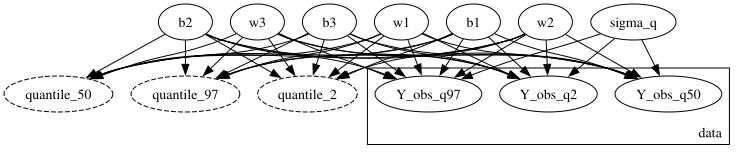

In [4]:
numpyro.render_model(
    quantile_gen_model,
    model_args=(X_test,),
)

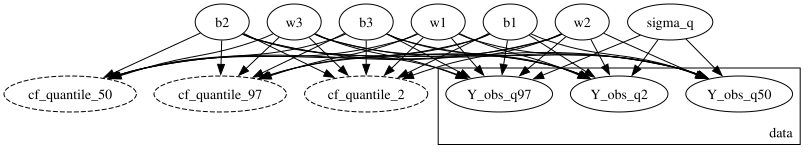

In [5]:
numpyro.render_model(
    quantile_cf_model,
    model_args=(X_test,),
)

In [6]:
# args = {
#     'num_warmup': 10,
#     'num_samples': 30,
#     'num_chains': 5,
# }
args = dict(
    num_warmup=50,
    num_samples=100,
    num_chains=1,
)

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Run MCMC


In [7]:
samples_gen = run_inference_bnn(quantile_gen_model, args, rng_key, X_train, Y_train_gen)

sample: 100%|██████████| 150/150 [16:03<00:00,  6.42s/it, 1023 steps of size 5.55e-04. acc. prob=0.74]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      0.79      0.15      0.80      0.58      0.97      3.33      2.02
     b1[1]      1.52      0.20      1.46      1.25      1.84      3.40      2.01
     b1[2]      2.51      0.09      2.50      2.39      2.69      9.33      1.03
     b1[3]     -1.10      0.11     -1.14     -1.23     -0.93      5.16      1.00
     b1[4]     -0.74      0.05     -0.74     -0.80     -0.65     11.57      0.99
     b1[5]     -0.39      0.09     -0.41     -0.49     -0.22      5.23      1.23
     b1[6]     -0.35      0.40     -0.46     -0.89      0.32      3.09      2.18
     b1[7]     -0.08      0.06     -0.07     -0.18      0.02     16.50      0.99
     b1[8]     -1.05      0.04     -1.05     -1.12     -0.99     19.02      0.99
     b1[9]      0.78      0.07      0.78      0.67      0.90      6.64      1.03
    b1[10]     -0.58      0.06     -0.60     -0.69     -0.49      9.76      1.39
    b1[11]      3.27      0

In [8]:
save_checkpoint(samples_gen, "quantile_gen_model", args, rng_key)

Saved checkpoint for model 'quantile_gen_model': ../checkpoints/quantile_gen_model_2025-11-13_10-15-38_gen.pkl


'../checkpoints/quantile_gen_model_2025-11-13_10-15-38_gen.pkl'

In [ ]:
# state_ckp = load_checkpoint(file_name="quantile_gen_model_2025-11-03_11-04-09_gen")
# samples_ckp = state_ckp["samples"]
# args_ckp = state_ckp["args"]
# rng_key_ckp = state_ckp["rng_key"]
# rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

In [9]:
preds_MCMC_gen = Predictive(quantile_gen_model, samples_gen)(rng_key_predict, X_test)

In [10]:
samples_cf = run_inference_bnn(quantile_cf_model, args, rng_key, X_train, Y_train_cf)

sample: 100%|██████████| 150/150 [21:06<00:00,  8.45s/it, 1023 steps of size 6.27e-04. acc. prob=0.56]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]     -1.13      0.13     -1.11     -1.33     -0.93      3.68      1.74
     b1[1]     -1.98      0.26     -1.94     -2.49     -1.66      5.69      0.99
     b1[2]      0.04      0.05      0.02     -0.01      0.15      5.34      1.38
     b1[3]     -1.21      0.14     -1.18     -1.43     -1.03      3.02      2.60
     b1[4]     -0.42      0.10     -0.40     -0.58     -0.27      4.13      1.88
     b1[5]      0.16      0.06      0.15      0.07      0.25      6.12      1.02
     b1[6]     -3.03      0.43     -3.11     -3.57     -2.28      4.30      1.16
     b1[7]     -0.65      0.07     -0.66     -0.77     -0.59      7.72      1.34
     b1[8]     -0.93      0.19     -0.94     -1.16     -0.62      2.94      2.50
     b1[9]      1.46      0.13      1.46      1.26      1.63      4.70      1.08
    b1[10]     -0.30      0.10     -0.25     -0.46     -0.19      3.66      1.51
    b1[11]      1.60      0

In [ ]:
# state_ckp = load_checkpoint(file_name="quantile_cf_model_2025-11-03_12-42-25_gen")
# samples_ckp = state_ckp["samples"]
# args_ckp = state_ckp["args"]
# rng_key_ckp = state_ckp["rng_key"]
# rng_key_ckp, rng_key_predict_ckp = random.split(rng_key_ckp)

In [11]:
preds_MCMC_cf = Predictive(quantile_cf_model, samples_cf)(rng_key_predict, X_test)

In [12]:
save_checkpoint(samples_cf, "quantile_cf_model", args, rng_key)

Saved checkpoint for model 'quantile_cf_model': ../checkpoints/quantile_cf_model_2025-11-13_10-36-47_gen.pkl


'../checkpoints/quantile_cf_model_2025-11-13_10-36-47_gen.pkl'

Run VI


In [ ]:
# guide = AutoNormal(quantile_cf_model)
# svi_result = run_svi(
#     quantile_cf_model, guide, rng_key, X_train, Y_train_cf, num_steps=1000
# )
# params = svi_result.params
# preds_VI_cf_logit = Predictive(
#     quantile_cf_model, guide=guide, params=params, num_samples=500
# )(rng_key_predict, X_test)
# preds_VI_cf = {k: jax.nn.sigmoid(v) for k, v in preds_VI_cf_logit.items()}

### Evaluation


In [25]:
preds = preds_MCMC_gen
# CF: preds_VI and preds_MCMC_cf
# Gen: preds_MCMC

In [26]:
# Check which model predictions we're using and extract quantiles accordingly
if "quantile_2" in preds:
    # Gen Model
    q025 = preds["quantile_2"].mean(axis=0)
    q50 = preds["quantile_50"].mean(axis=0)
    q975 = preds["quantile_97"].mean(axis=0)
    print("Using Gen model quantiles")
elif "cf_quantile_2" in preds:
    # CF Model
    q025 = preds["cf_quantile_2"].mean(axis=0)
    q50 = preds["cf_quantile_50"].mean(axis=0)
    q975 = preds["cf_quantile_97"].mean(axis=0)
    print("Using CF model quantiles")
else:
    raise KeyError(
        f"No quantile predictions found. Available keys: {list(preds.keys())}"
    )

Using Gen model quantiles


In [27]:
# Count violations (should be 0)
violations_lower = (q025 > q50).sum()
violations_upper = (q50 > q975).sum()
negative_vals = (q025 < 0).sum()

print(f"Lower > Median violations: {violations_lower} (should be 0)")
print(f"Median > Upper violations: {violations_upper} (should be 0)")
print(f"Negative quantiles: {negative_vals} (should be 0)")
print(f"Min spacing (2.5%→50%): {(q50 - q025).min():.4f}")
print(f"Min spacing (50%→97.5%): {(q975 - q50).min():.4f}")

Lower > Median violations: 0 (should be 0)
Median > Upper violations: 0 (should be 0)
Negative quantiles: 0 (should be 0)
Min spacing (2.5%→50%): 0.0000
Min spacing (50%→97.5%): 20.9413


In [16]:
preds.keys()

dict_keys(['Y_obs_q2', 'Y_obs_q50', 'Y_obs_q97', 'cf_quantile_2', 'cf_quantile_50', 'cf_quantile_97'])

In [28]:
rmse = jnp.sqrt(jnp.mean((q50 - Y_test_gen) ** 2))  # * Y_test_aval
print("Test RMSE (Median):", rmse)

Test RMSE (Median): 69.30808


In [18]:
rmse = jnp.sqrt(jnp.mean((q50 * Y_test_aval - Y_test_gen) ** 2))
print("Test RMSE (Cf, Median):", rmse)

Test RMSE (Cf, Median): 70.5164


Empirical coverage of percentiles


In [29]:
inside = (Y_test_gen >= q025) & (Y_test_gen <= q975)
coverage_90 = inside.mean()
print(f"Empirical coverage (0.025–0.975): {coverage_90:.3f}")

below_median = (Y_test_gen <= q50).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

Empirical coverage (0.025–0.975): 0.864
Below median (should be ~0.5): 0.374


In [19]:
inside = (Y_test_cf >= q025) & (Y_test_cf <= q975)
coverage_90 = inside.mean()
print(f"Empirical coverage cf (0.05–0.95): {coverage_90:.3f}")

below_median = (Y_test_cf <= q50).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

Empirical coverage cf (0.05–0.95): 0.908
Below median (should be ~0.5): 0.395


### Plots


Variational Inference loss


In [ ]:
# losses = svi_result.losses
# print(f"Final ELBO loss: {losses[-1]:.3f}")
# plt.plot(losses)
# plt.title("ELBO over training")
# plt.xlabel("Iteration")
# plt.ylabel("−ELBO")
# plt.show()

Different intervals (percentile vs. hdi vs. normal)


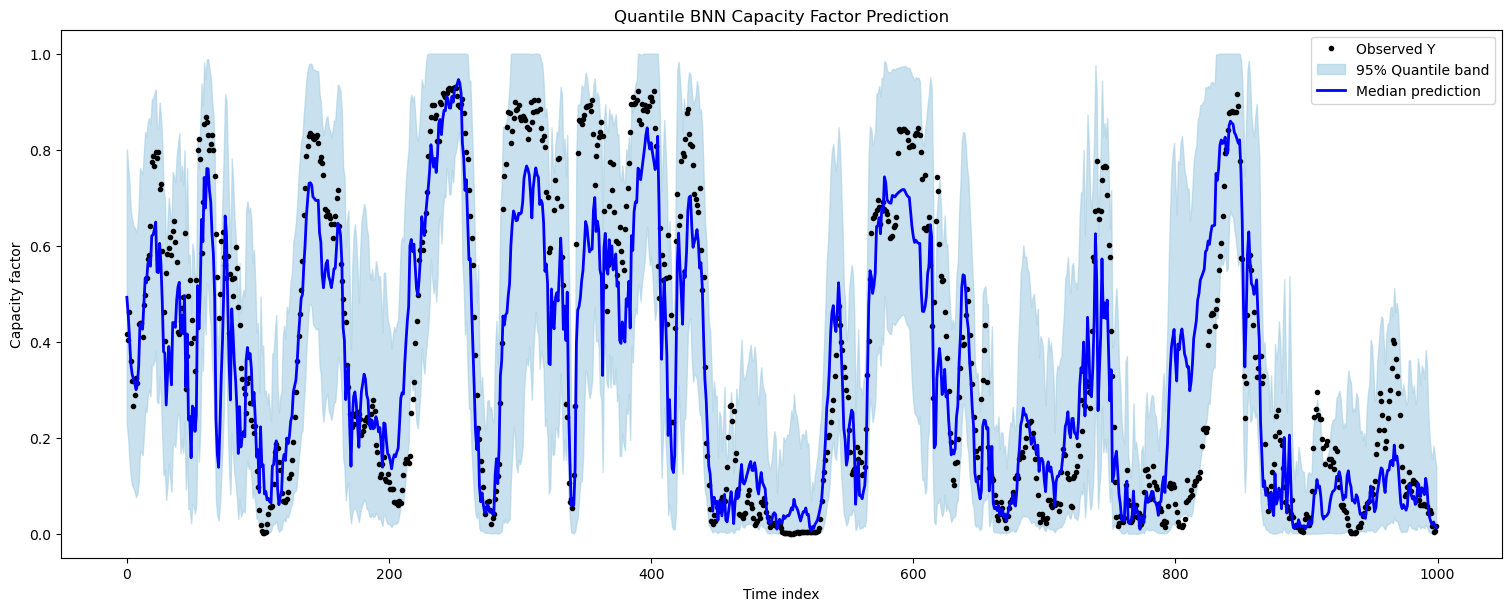

In [20]:
# Plot 95% CI, Capacity factor
n_plot = 1000
X_new = np.arange(n_plot)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(X_new, Y_test_cf[:n_plot], ".", color="black", label="Observed Y")
ax.fill_between(
    X_new,
    q025[:n_plot],
    q975[:n_plot],
    color="#A6CEE3",
    alpha=0.6,
    label="95% Quantile band",
)
ax.plot(X_new, q50[:n_plot], color="blue", lw=2, label="Median prediction")
ax.set(
    xlabel="Time index",
    ylabel="Capacity factor",
    title="Quantile BNN Capacity Factor Prediction",
)
ax.legend()
plt.show()


Histogram of q50:


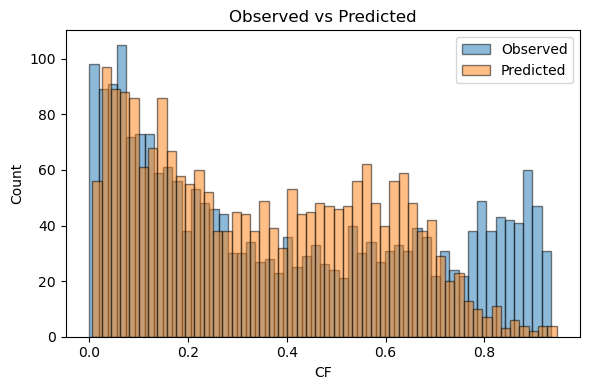

In [23]:
print("\nHistogram of q50:")
plt.figure(figsize=(6, 4))
plt.hist(Y_test_cf, bins=50, edgecolor="black", alpha=0.5, label="Observed")
plt.hist(q50, bins=50, edgecolor="black", alpha=0.5, label="Predicted")
plt.xlabel("CF")
plt.ylabel("Count")
plt.title("Observed vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

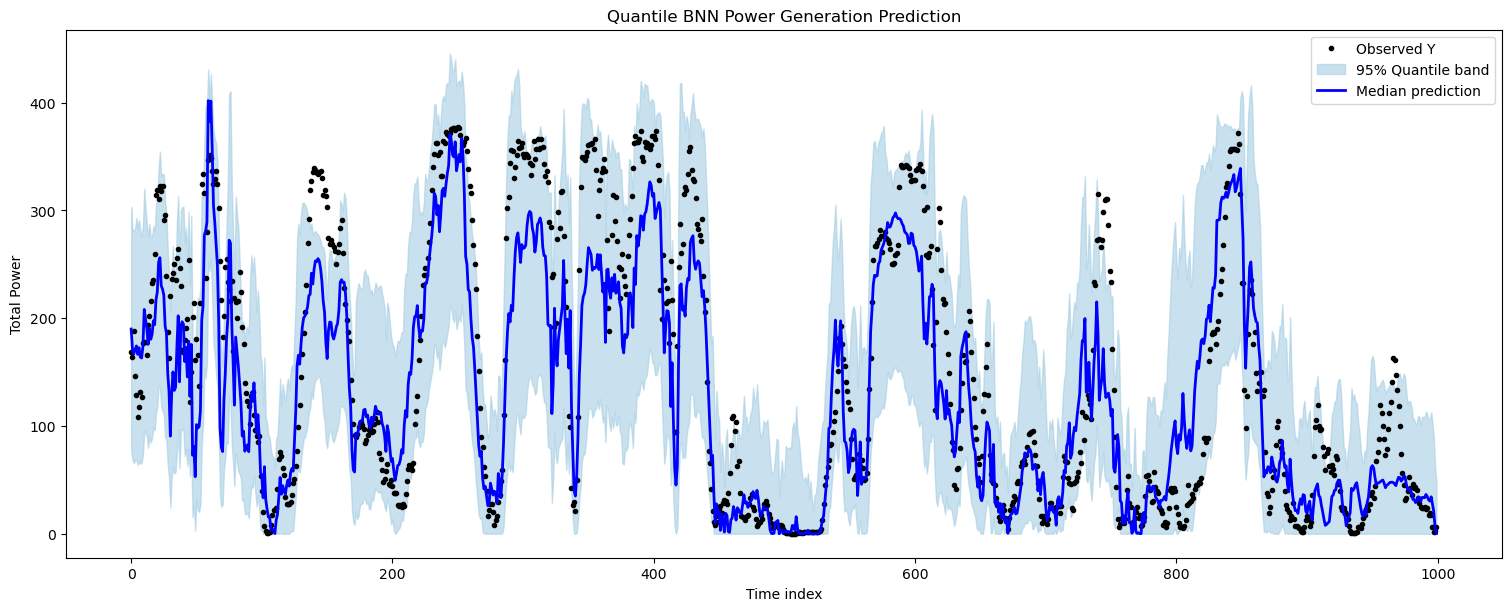

In [30]:
# Plot 95% CI, Generation
n_plot = 1000
X_new = np.arange(n_plot)
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(X_new, Y_test_gen[:n_plot], ".", color="black", label="Observed Y")
ax.fill_between(
    X_new,
    q025[:n_plot],
    q975[:n_plot],
    color="#A6CEE3",
    alpha=0.6,
    label="95% Quantile band",
)
ax.plot(X_new, q50[:n_plot], color="blue", lw=2, label="Median prediction")
ax.set(
    xlabel="Time index",
    ylabel="Total Power",
    title="Quantile BNN Power Generation Prediction",
)
ax.legend()
plt.show()

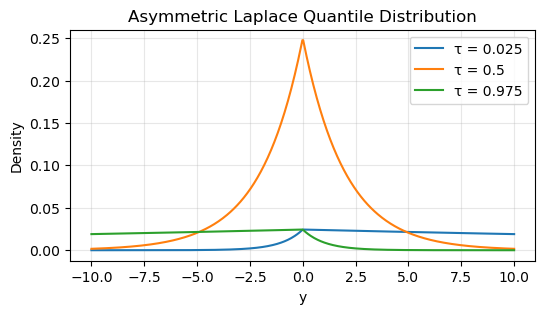

In [31]:
loc = 0.0
scale = 1.0
quantiles = [0.025, 0.5, 0.975]

x = jnp.linspace(-10, 10, 500)

plt.figure(figsize=(6, 3))
for q in quantiles:
    d = dist.AsymmetricLaplaceQuantile(loc=loc, scale=scale, quantile=q)
    pdf = jnp.exp(d.log_prob(x))
    plt.plot(x, pdf, label=f"τ = {q}")

plt.title("Asymmetric Laplace Quantile Distribution")
plt.xlabel("y")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

PIT (Probability Integral Transform)

- Checks calibration of probabilistic forecasts
- Model well-calibrated -> values uniformly distributed
- For each observation $y_i$:
  - Take all model’s predictive samples for that data point
  - Compute how many of those samples are less than or equal to the actual observed value
  - PIT value $u_i = P_{\hat{Y_i}}​​(Y\leq y)$
  - with MCMC: $u_i \approx \frac{1}{S} \sum_{s=1}^S 1[y_i^{(s)}\leq y_i]$


PIT mean: 0.6119898195279964 (should be uniform if calibrated)


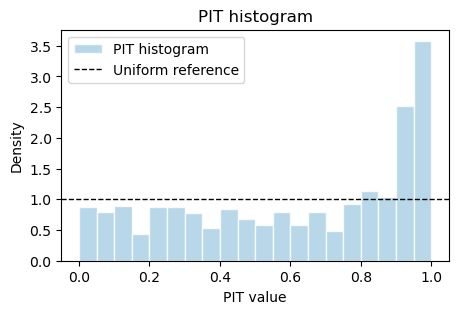

In [32]:
pits = np.array(
    [
        percentileofscore(preds["Y_obs_q50"][:, t], Y_test_gen[t], kind="mean") / 100.0
        for t in range(preds["Y_obs_q50"].shape[1])
    ]
)
pits_mean = pits.mean()
print(f"PIT mean: {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5, 3))
plt.hist(
    pits,
    bins=20,
    range=(0, 1),
    density=True,
    alpha=0.8,
    color="#A6CEE3",
    edgecolor="white",
    label="PIT histogram",
)
plt.axhline(1.0, color="k", ls="--", lw=1, label="Uniform reference")
plt.xlabel("PIT value")
plt.ylabel("Density")
plt.title("PIT histogram")
plt.legend()
plt.show()